### 이진분류
: Banknote Authentication 데이터 셋 - 진짜 지폐와 가짜 지폐 판별
- 데이터: 1372개
- 정답: 0=진짜, 1=가짜
- 입력특징: 4개
    - variance(분산)
    - skewness(왜도): 좌우 어느 방향으로 치우쳐져 있는지
    - curtosis(첨도): 분포의 뾰족한 정도
    - entropy(엔트로피): 낮으면 특정 값이나 패턴에 집중되어 있다는 것, 높으면 다양한 값이 나타나고 분포가 복잡해지는 경향
- 4개의 특징값(입력값)으로 사용하고, 결과 예측

In [17]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import matplotlib.pyplot as plt
import numpy as np
import random

#### step 1. 데이터 불러오기 및 전처리

In [ ]:
cnm = ["variance", "skewness", "curtosis", "entropy", "class"]
df = pd.read_csv("data_banknote_authentication.txt", names=cnm)
print(df.head())
print("데이터 크기:", df.shape)
print("클래스 별 데이터 개수:")
print(df["class"].value_counts().sort_index())

   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0
데이터 크기: (1372, 5)
클래스 별 데이터 개수:
class
0    762
1    610
Name: count, dtype: int64


In [8]:
# 입력데이터(x)와 정답데이터(y) 분리
x = torch.tensor(
    df[["variance", "skewness", "curtosis", "entropy"]].values, dtype=torch.float32
)
y = torch.tensor(df["class"].values, dtype=torch.float32).reshape(-1, 1)
# 클래스별로 학습/테스트 데이터를 나눔
torch.manual_seed(42)
train_indices = []
test_indices = []
for cv in [0, 1]:
    # class_indices = []
    # for i in range(len(y)):
    #     if y[i].item() == cv:
    #         class_indices.append(i)
    # random.shuffle(class_indices)  # 순서를 무작위로 섞기

    # where: 조건을 만족하는 데이터 찾아 튜플 반환
    class_indices = torch.where(y.squeeze() == cv)[0]
    class_indices = class_indices[torch.randperm(len(class_indices))]
    split = int(len(class_indices) * 0.8)  # 학습 80%, 테스트 20% 분리
    train_indices.extend(class_indices[:split])
    test_indices.extend(class_indices[split:])
# 학습/테스트 데이터 섞기(클래스0 앞쪽에, 클래스1 뒤쪽에 몰려있는 것 섞기)
train_indices = torch.tensor(train_indices)[torch.randperm(len(train_indices))]
test_indices = torch.tensor(test_indices)[torch.randperm(len(test_indices))]
xtr = x[train_indices]
xte = x[test_indices]
ytr = y[train_indices]
yte = y[test_indices]
# 데이터 정규화, 데이터의 편차가 클 때 평균 0, 표준편차가 1로 정규화 후 학습
mean = xtr.mean(dim=0)  # 행의 방향, 즉 열의 평균
std = xtr.std(dim=0).clamp(min=1e-8)
xtr = (xtr - mean) / std
xte=(xte-mean)/std
print(xtr.shape, xte.shape)
print(ytr.shape, yte.shape)

torch.Size([1097, 4]) torch.Size([275, 4])
torch.Size([1097, 1]) torch.Size([275, 1])


In [10]:
# DataLoader 생성
BATCH_SIZE = 32
trds = TensorDataset(xtr, ytr)
teds = TensorDataset(xte, yte)
trdl = DataLoader(trds, batch_size=BATCH_SIZE, shuffle=True)
tedl = DataLoader(teds, batch_size=BATCH_SIZE, shuffle=False)
n = len(trdl.dataset)
print(n)

1097


In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(
            nn.Linear(4, 100), nn.Sigmoid(), nn.Linear(100, 1), nn.Sigmoid()
        )

    def forward(self, x):
        x = self.linear(x)
        return x


m = MLP()

In [21]:
LR = 1e-1
EPOCH = 100
op = optim.SGD(m.parameters(), lr=LR)
cri = nn.BCELoss()
lh = []
m.train()
for ep in range(EPOCH):
    rloos = 0
    for xb, yb in trdl:
        yh = m(xb)
        loss = cri(yh, yb)
        op.zero_grad()
        loss.backward()
        op.step()
        loss += loss.item() * xb.shape[0]
    eloss = loss / n
    lh.append(eloss.item())
    print(f"EPOCH: {ep+1}, train loss: {eloss:.4f}")

EPOCH: 1, train loss: 0.0007
EPOCH: 2, train loss: 0.0000
EPOCH: 3, train loss: 0.0001
EPOCH: 4, train loss: 0.0001
EPOCH: 5, train loss: 0.0000
EPOCH: 6, train loss: 0.0001
EPOCH: 7, train loss: 0.0001
EPOCH: 8, train loss: 0.0001
EPOCH: 9, train loss: 0.0001
EPOCH: 10, train loss: 0.0005
EPOCH: 11, train loss: 0.0003
EPOCH: 12, train loss: 0.0000
EPOCH: 13, train loss: 0.0003
EPOCH: 14, train loss: 0.0008
EPOCH: 15, train loss: 0.0003
EPOCH: 16, train loss: 0.0001
EPOCH: 17, train loss: 0.0001
EPOCH: 18, train loss: 0.0000
EPOCH: 19, train loss: 0.0000
EPOCH: 20, train loss: 0.0002
EPOCH: 21, train loss: 0.0003
EPOCH: 22, train loss: 0.0001
EPOCH: 23, train loss: 0.0000
EPOCH: 24, train loss: 0.0001
EPOCH: 25, train loss: 0.0007
EPOCH: 26, train loss: 0.0010
EPOCH: 27, train loss: 0.0000
EPOCH: 28, train loss: 0.0001
EPOCH: 29, train loss: 0.0000
EPOCH: 30, train loss: 0.0002
EPOCH: 31, train loss: 0.0002
EPOCH: 32, train loss: 0.0008
EPOCH: 33, train loss: 0.0001
EPOCH: 34, train lo

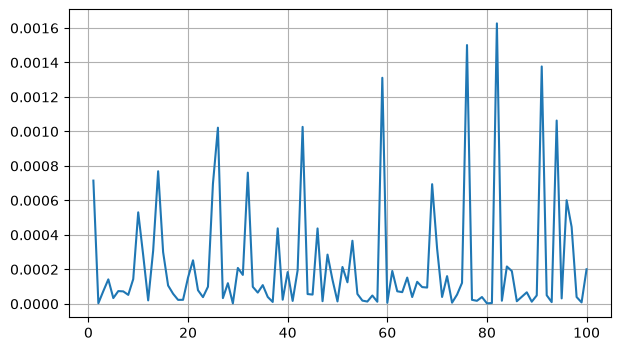

In [22]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCH + 1), lh)
plt.grid()

#### step 4. 모델 테스트 하기

In [20]:
m.eval()
correct = 0
total = 0
with torch.no_grad():
    for xb, yb in tedl:
        yh = m(xb)
        pr = (yh >= 0.5).float()
        correct += (pr == yb).sum().item()
        total += yb.numel()
accuracy = correct / total * 100
print(f"Test accuracy: {correct}/{total}({accuracy:.1f}%)")

Test accuracy: 267/275(97.1%)


#### step 5. 테스트 결과 시각화

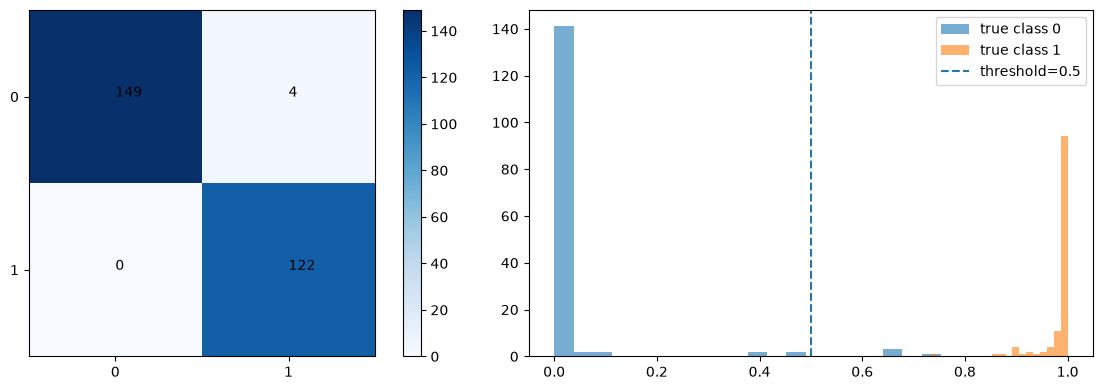

In [27]:
m.eval()
yta = []  # 정답 전체
ypa = []  # 예측 전체
with torch.no_grad():
    for xb, yb in tedl:
        yh = m(xb)
        yta.append(yb.numpy().reshape(-1))
        ypa.append(yh.numpy().reshape(-1))
# 배치별로 나눠 저장했던 실제 정답 배열을 하나로 합친 후 데이터 타입을 정수 변환
yt = np.concatenate(yta).astype(int)
yp = np.concatenate(ypa)
ypr = (yp >= 0.5).astype(int)
# 혼동 행렬: 행은 실제 클래스, 열은 예측 클래스
cm = np.zeros((2, 2), dtype=int)
for t, p in zip(yt, ypr):
    cm[t, p] += 1
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_xticks([0, 1], labels=["0", "1"])
axes[0].set_yticks([0, 1], labels=["0", "1"])
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j])
fig.colorbar(im, ax=axes[0])
# 클래스 별 예측 확률 분포
axes[1].hist(yp[yt == 0], bins=20, alpha=0.6, label="true class 0")
axes[1].hist(yp[yt == 1], bins=20, alpha=0.6, label="true class 1")
axes[1].axvline(0.5, linestyle="--", label="threshold=0.5")
axes[1].legend()
plt.tight_layout()
plt.show()